# Filtering complex rules

In [11]:
import os
import sys

import pandas as pd

sys.path[:0] = [os.path.abspath("scripts"), os.path.abspath(".."), os.path.abspath("../differential_rules/scripts")]
import data_helper as dh
import significance_histograms_vis as sh

In [12]:
MAX_FDR = 0.05
P_CUT = 0.05
PREFIX = "filtering"
LABELS = sh.group_labels(P_CUT, MAX_FDR)
P_LINE = (P_CUT, f"p = {P_CUT}")

In [14]:
rules = dh._read_rules(dh.RESULT_CSV_PATH, rule_max_items=4)
complex_rules = rules[rules.Rule_Type.ne("pairwise")]
level = sh.pairwise_or_complex(rules)
shape = sh.shape_and_size(rules)
significant = sh.significance(rules, P_CUT, MAX_FDR)

Read results_CN_pairwise.csv + results_CN_complex.csv


In [15]:
stages = pd.DataFrame({"all": True,
                       f"p ≤ {P_CUT}": rules.P_Value <= P_CUT,
                       f"FDR ≤ {MAX_FDR}": rules.Individual_FDR <= MAX_FDR,
                       f"conditional ≤ {MAX_FDR}": rules.conditional_fdr <= MAX_FDR})
per_fov = stages.groupby([rules.FOV, shape], observed=True).sum()

print(f"{rules.FOV.nunique()} fields")
display(stages.groupby(shape, observed=True).sum())
display(per_fov.groupby(level=1, observed=True).describe().drop(columns=["count", "std"], level=1).T.round(1))

288 fields


,all,p ≤ 0.05,FDR ≤ 0.05,conditional ≤ 0.05
Pairwise,16600,10877,7537,0
Multiple antecedents · 3 items,139872,76631,42188,20
Multiple antecedents · 4 items,479955,244317,82259,0
Multiple consequents · 3 items,60114,31716,16830,19
Multiple consequents · 4 items,101891,44157,13655,0


Pairwise  Multiple antecedents · 3 items  \
all                mean      57.6                           485.7   
                   min        9.0                            58.0   
                   25%       42.0                           331.5   
                   50%       56.5                           466.0   
                   75%       73.0                           633.2   
                   max      112.0                          1016.0   
p ≤ 0.05           mean      37.8                           266.1   
                   min        4.0                            42.0   
                   25%       28.8                           184.8   
                   50%       38.0                           262.0   
                   75%       47.0                           344.5   
                   max       79.0                           682.0   
FDR ≤ 0.05         mean      26.2                           146.5   
                   min        0.0                             0.0   
                   25%       18.0                            81.0   
                   50%       25.0                           136.0   
                   75%       33.0                           196.0   
                   max       67.0                           526.0   
conditional ≤ 0.05 mean       0.0                             0.1   
                   min        0.0                             0.0   
                   25%        0.0                             0.0   
                   50%        0.0                             0.0   
                   75%        0.0                             0.0   
                   max        0.0                            20.0   

                         Multiple antecedents · 4 items  \
all                mean                          1666.5   
                   min                             85.0   
                   25%                           1060.8   
                   50%                           1587.0   
                   75%                           2176.2   
                   max                           4096.0   
p ≤ 0.05           mean                           848.3   
                   min                             73.0   
                   25%                            530.2   
                   50%                            790.0   
                   75%                           1069.8   
                   max                           2908.0   
FDR ≤ 0.05         mean                           285.6   
                   min                              0.0   
                   25%                              0.0   
                   50%                            227.0   
                   75%                            489.0   
                   max                           1728.0   
conditional ≤ 0.05 mean                             0.0   
                   min                              0.0   
                   25%                              0.0   
                   50%                              0.0   
                   75%                              0.0   
                   max                              0.0   

                         Multiple consequents · 3 items  \
all                mean                           208.7   
                   min                             33.0   
                   25%                            149.0   
                   50%                            202.0   
                   75%                            268.2   
                   max                            425.0   
p ≤ 0.05           mean                           110.1   
                   min                             18.0   
                   25%                             69.0   
                   50%                            109.5   
                   75%                            141.2   
                   max                            310.0   
FDR ≤ 0.05         mean                            58.4 

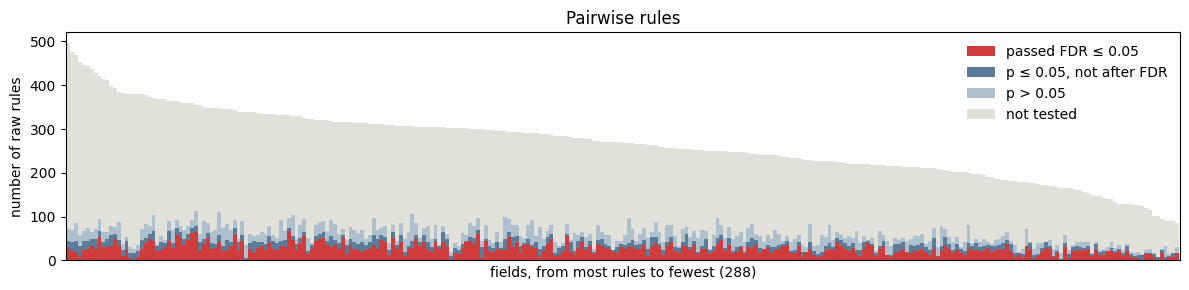

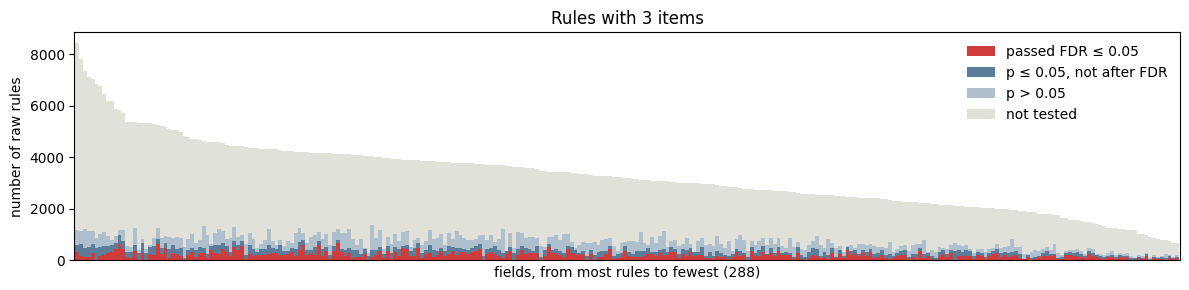

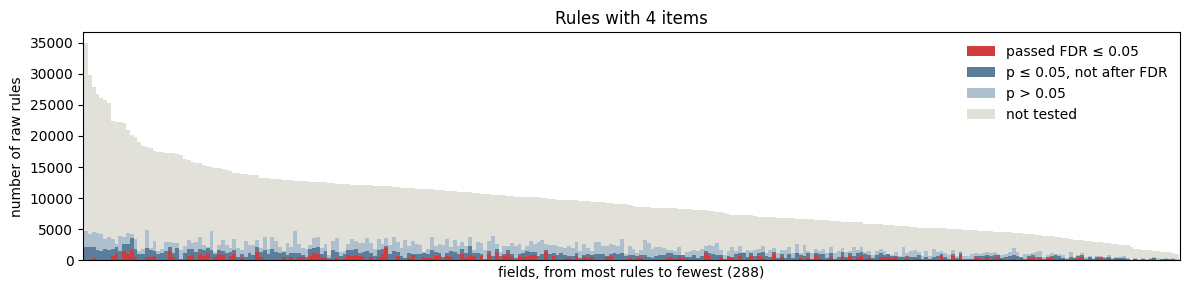

In [16]:
raw = pd.read_csv(os.path.join(dh.RESULT_CSV_PATH, "results_CN_RAW.csv"), usecols=["FOV", "len_ant", "len_con"])
sh.field_bars(rules, significant, LABELS, raw)

## 1. Rule p-values
Each rule's own shuffle test. Light: p above the cut; dark: p at or below it; red: passed the FDR cut.

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_p_values_Pairwise.pdf


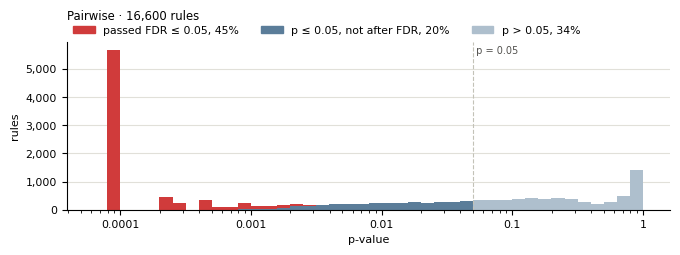

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_p_values_Complex.pdf


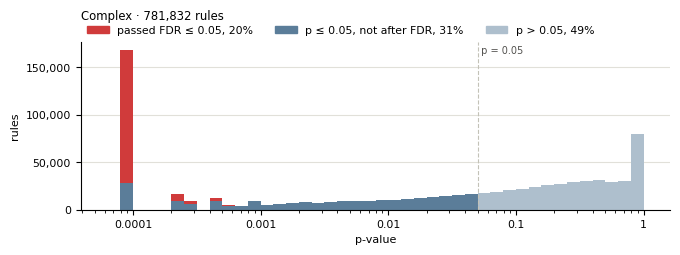

In [17]:
sh.histograms(sh.counts(rules.P_Value, level, significant, sh.P_BINS),
              sh.P_BINS, LABELS, "p-value", "rules", f"{PREFIX}_p_values", P_LINE)

### By shape and size

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_p_values_by_shape_Pairwise.pdf


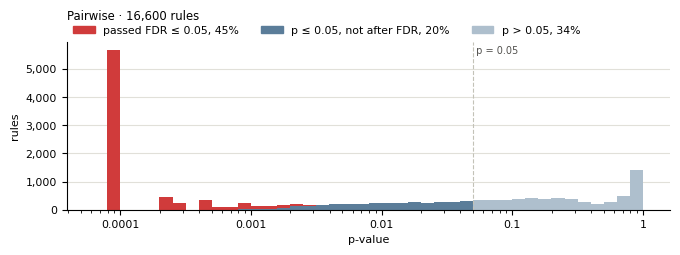

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_p_values_by_shape_Multiple_antecedents_3_items.pdf


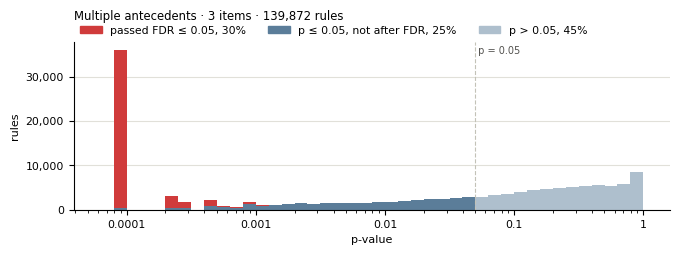

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_p_values_by_shape_Multiple_antecedents_4_items.pdf


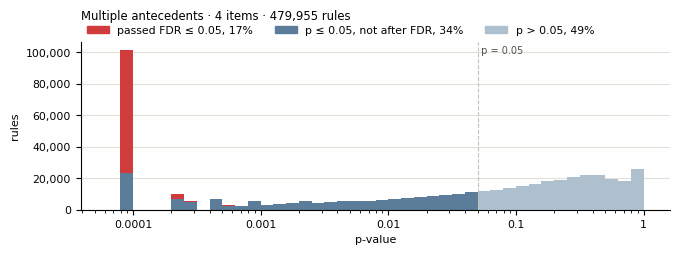

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_p_values_by_shape_Multiple_consequents_3_items.pdf


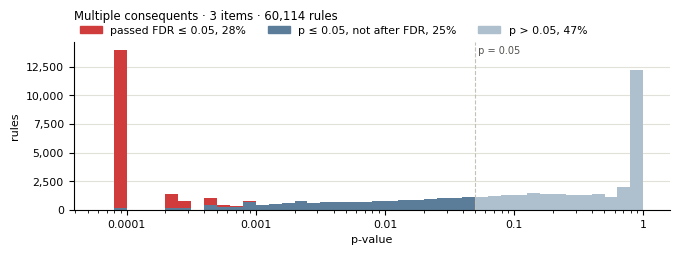

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_p_values_by_shape_Multiple_consequents_4_items.pdf


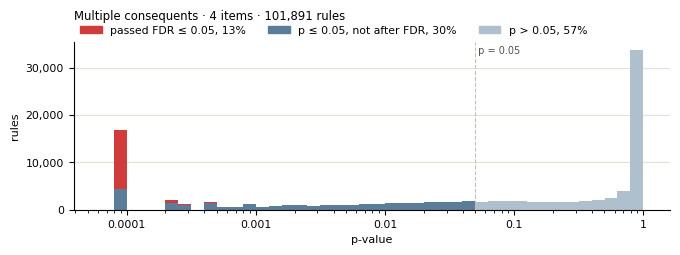

In [18]:
sh.histograms(sh.counts(rules.P_Value, shape, significant, sh.P_BINS),
              sh.P_BINS, LABELS, "p-value", "rules", f"{PREFIX}_p_values_by_shape", P_LINE)

## 2. Conditional p-values
Complex rules tested against their significant simpler rules: the largest p over those comparisons.

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_conditional_p_values_Complex.pdf


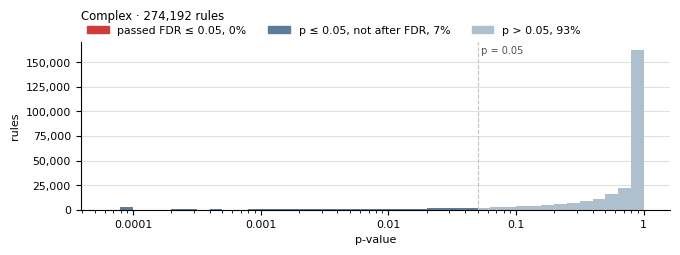

In [19]:
conditional = sh.significance(complex_rules, P_CUT, MAX_FDR, "conditional_p_value", "conditional_fdr")
sh.histograms(sh.counts(complex_rules.conditional_p_value, level[complex_rules.index], conditional, sh.P_BINS),
              sh.P_BINS, LABELS, "p-value", "rules", f"{PREFIX}_conditional_p_values", P_LINE)

## 3. Lift and conviction in the shuffles
Every shuffled value of every rule, coloured by its rule's own test. Values beyond the axis are drawn at its ends: lift 0 on the left, infinite conviction on the right. Reads every field's shuffles, about 30 minutes.

In [20]:
shuffled = sh.shuffled_counts(rules, shape, significant)

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_shuffled_lift_Pairwise.pdf


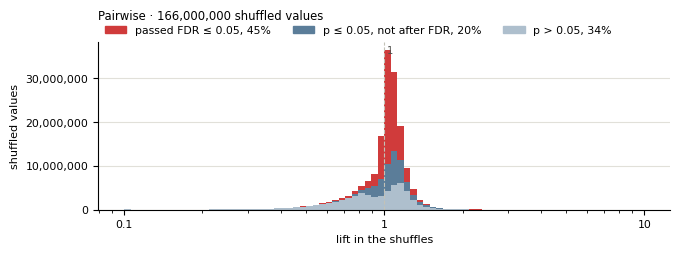

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_shuffled_lift_Multiple_antecedents_3_items.pdf


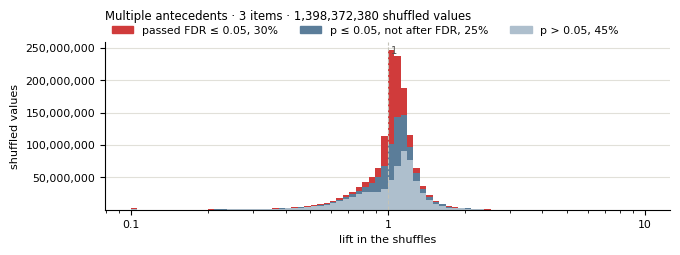

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_shuffled_lift_Multiple_antecedents_4_items.pdf


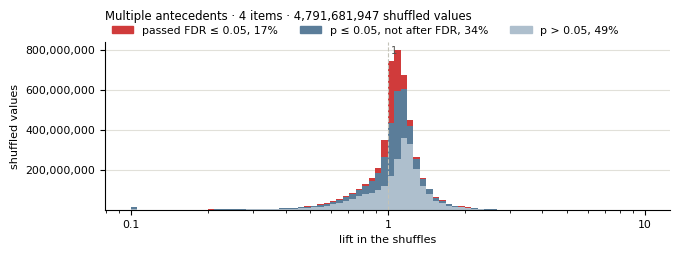

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_shuffled_lift_Multiple_consequents_3_items.pdf


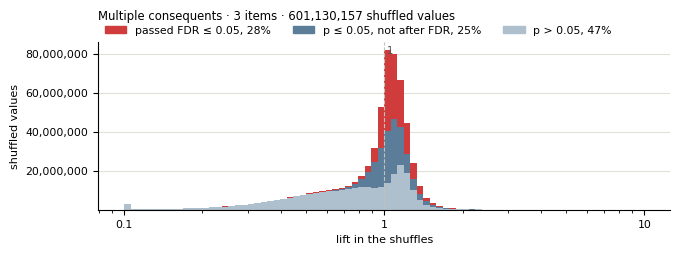

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_shuffled_lift_Multiple_consequents_4_items.pdf


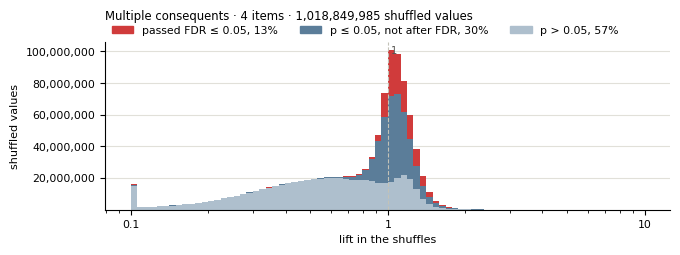

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_shuffled_conviction_Pairwise.pdf


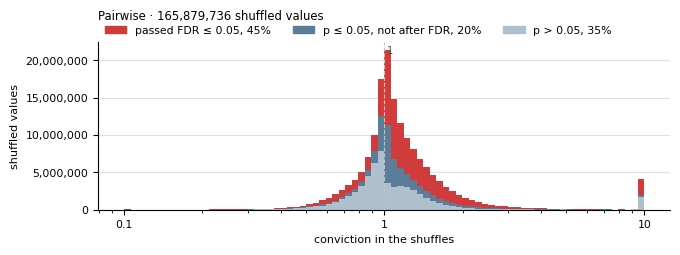

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_shuffled_conviction_Multiple_antecedents_3_items.pdf


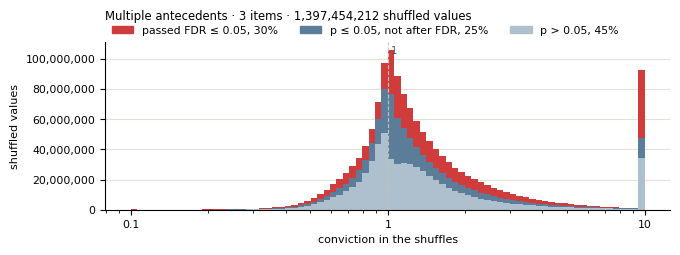

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_shuffled_conviction_Multiple_antecedents_4_items.pdf


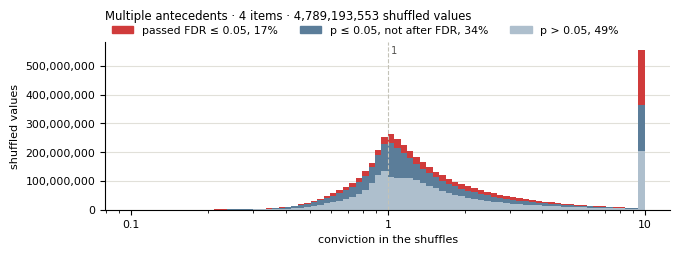

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_shuffled_conviction_Multiple_consequents_3_items.pdf


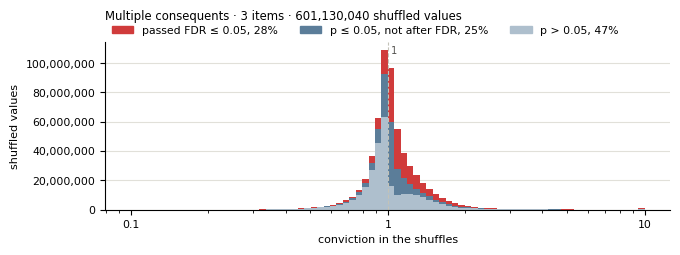

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_shuffled_conviction_Multiple_consequents_4_items.pdf


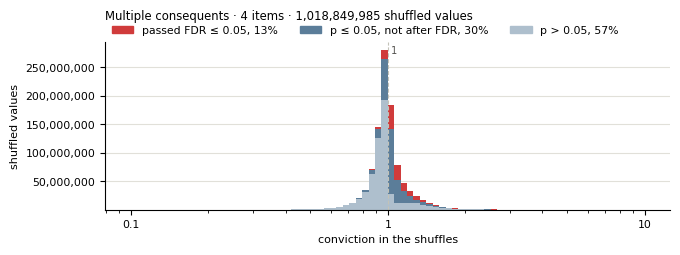

In [21]:
def plot_shuffled(shuffled, name):
    for metric, table in shuffled.items():
        sh.histograms(table, sh.METRIC_BINS, LABELS, f"{metric} in the shuffles", "shuffled values",
                      f"{PREFIX}_{name}_{metric}", (1, "1"))

plot_shuffled(shuffled, "shuffled")

## 4. Lift and conviction in the conditional shuffles
The same, for the shuffles that kept a shorter rule's cell types in place. Each batch counts only the complex rules it tested, coloured by their conditional test. A rule tested against two shorter rules is counted in both batches.

In [22]:
comparisons = pd.read_csv(os.path.join(dh.RESULT_CSV_PATH, "results_CN_comparisons.csv"),
                          usecols=["FOV", "rule_idx", "fixed_types", "status"])
conditional_shuffled = sh.shuffled_counts(complex_rules, shape[complex_rules.index], conditional,
                                          tested=sh.tested_by_batch(comparisons))

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_conditional_shuffled_lift_Multiple_antecedents_3_items.pdf


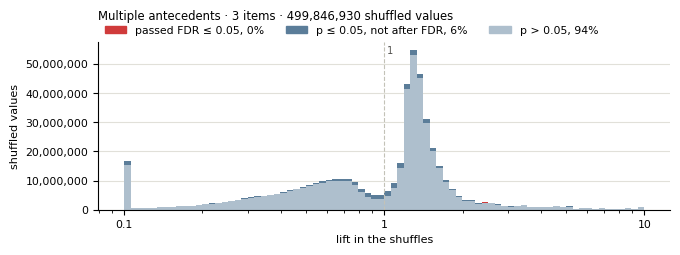

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_conditional_shuffled_lift_Multiple_antecedents_4_items.pdf


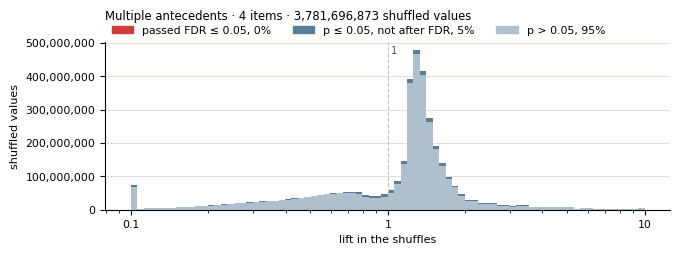

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_conditional_shuffled_lift_Multiple_consequents_3_items.pdf


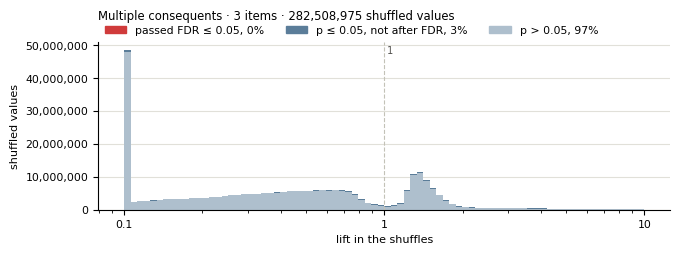

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_conditional_shuffled_lift_Multiple_consequents_4_items.pdf


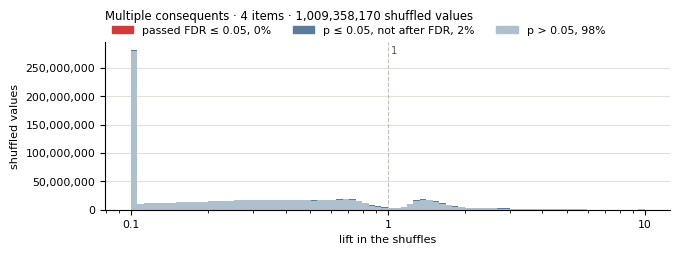

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_conditional_shuffled_conviction_Multiple_antecedents_3_items.pdf


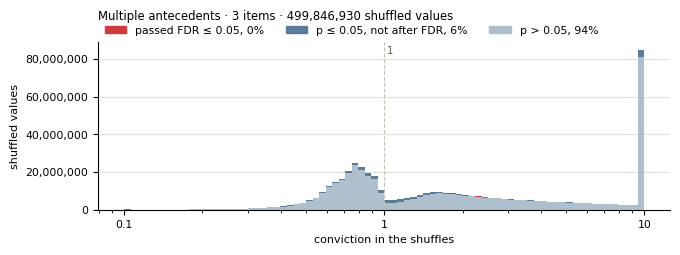

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_conditional_shuffled_conviction_Multiple_antecedents_4_items.pdf


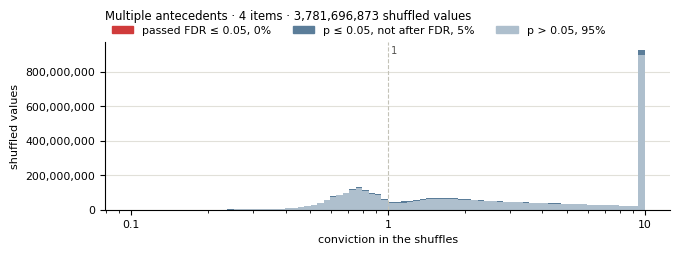

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_conditional_shuffled_conviction_Multiple_consequents_3_items.pdf


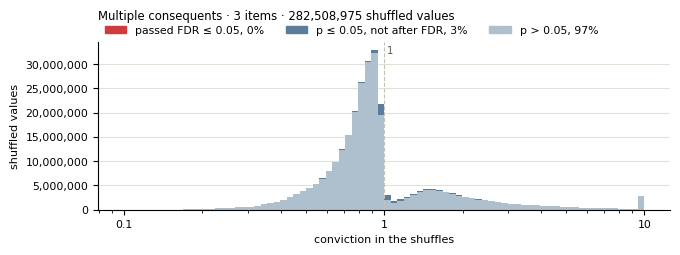

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\filtering_conditional_shuffled_conviction_Multiple_consequents_4_items.pdf


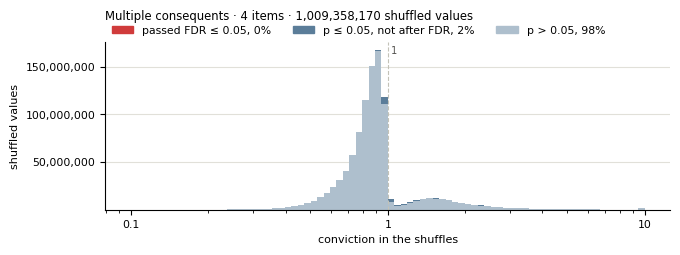

In [26]:
plot_shuffled(conditional_shuffled, "conditional_shuffled")